In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
train = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/train.csv')
test = pd.read_csv('/kaggle/input/competitions/house-prices-advanced-regression-techniques/test.csv')
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [3]:
train.shape , test.shape

((1460, 81), (1459, 80))

In [4]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
train.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

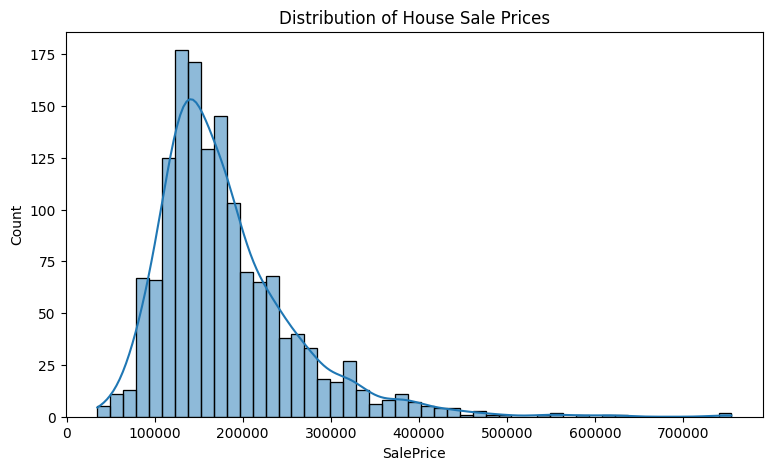

In [7]:
plt.figure(figsize=(9, 5))
sns.histplot(train["SalePrice"], kde=True)
plt.title("Distribution of House Sale Prices")
plt.show()

In [8]:
train['SalePrice'].skew()

np.float64(1.8828757597682129)

<Axes: xlabel='LogSalePrice', ylabel='Count'>

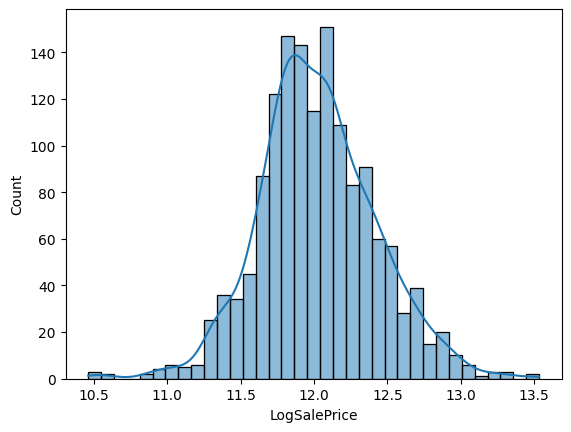

In [9]:
train["LogSalePrice"] = np.log1p(train["SalePrice"])

sns.histplot(train["LogSalePrice"], kde=True)

In [10]:
from sklearn.model_selection import train_test_split

# Drop target columns and the identifier from FEATURES (not rows).
X = train.drop(columns=['SalePrice', 'LogSalePrice', 'Id'], errors='ignore')
y = np.log1p(train['SalePrice'])

# Catch target leakage before preprocessing.
assert 'SalePrice' not in X.columns and 'LogSalePrice' not in X.columns
print('Feature count:', X.shape[1])

Feature count: 79


In [11]:
X_train ,X_val  , y_train , y_val = train_test_split(X , y , test_size = 0.2 , random_state=42)
X_train.shape , X_val.shape

((1168, 79), (292, 79))

In [12]:
missing = X_train.isnull().sum()
missing

MSSubClass         0
MSZoning           0
LotFrontage      217
LotArea            0
Street             0
                ... 
MiscVal            0
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
Length: 79, dtype: int64

In [13]:
missing = missing[missing > 0].sort_values(ascending = False)
missing

PoolQC          1162
MiscFeature     1122
Alley           1094
Fence            935
MasVnrType       683
FireplaceQu      547
LotFrontage      217
GarageType        64
GarageYrBlt       64
GarageFinish      64
GarageQual        64
GarageCond        64
BsmtCond          28
BsmtFinType1      28
BsmtExposure      28
BsmtQual          28
BsmtFinType2      28
MasVnrArea         6
Electrical         1
dtype: int64

In [14]:
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
print('Numerical:', len(num_cols), 'Categorical:', len(cat_cols))

Numerical: 36 Categorical: 43


In [15]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy='median')
X_train_num = pd.DataFrame(
    num_imputer.fit_transform(X_train[num_cols]),
    columns=num_cols,
    index=X_train.index
)
X_val_num = pd.DataFrame(
    num_imputer.transform(X_val[num_cols]),
    columns=num_cols,
    index=X_val.index
)

In [16]:
cat_imputer = SimpleImputer(strategy='constant', fill_value='Missing')
X_train_cat = pd.DataFrame(
    cat_imputer.fit_transform(X_train[cat_cols]),
    columns=cat_cols,
    index=X_train.index
)
X_val_cat = pd.DataFrame(
    cat_imputer.transform(X_val[cat_cols]),
    columns=cat_cols,
    index=X_val.index
)

In [17]:
X_train_clean  = pd.concat([X_train_num , X_train_cat] , axis = 1)
X_val_clean = pd.concat([X_val_num , X_val_cat] , axis = 1)

In [18]:
X_train_clean.isnull().sum().sum() , X_val_clean.isnull().sum().sum()

(np.int64(0), np.int64(0))

In [19]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_encoded = encoder.fit_transform(
    X_train_clean[cat_cols]
)

X_val_encoded = encoder.transform(
    X_val_clean[cat_cols]
)

In [20]:
encoded_cols = encoder.get_feature_names_out(cat_cols)

X_train_encoded = pd.DataFrame(
    X_train_encoded, columns=encoded_cols, index=X_train_clean.index
)
X_val_encoded = pd.DataFrame(
    X_val_encoded, columns=encoded_cols, index=X_val_clean.index
)

X_train_final = pd.concat([X_train_clean[num_cols], X_train_encoded], axis=1)
X_val_final = pd.concat([X_val_clean[num_cols], X_val_encoded], axis=1)

# Both matrices must have identical columns, with no target leakage.
assert X_train_final.columns.equals(X_val_final.columns)
assert not any('saleprice' in col.lower() for col in X_train_final.columns)
print('Training features:', X_train_final.shape)
print('Validation features:', X_val_final.shape)

Training features: (1168, 301)
Validation features: (292, 301)


In [21]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()

lr.fit(X_train_final, y_train)

LinearRegression()

In [22]:
y_train_pred = lr.predict(X_train_final)
y_val_pred =lr.predict(X_val_final)

In [23]:
from sklearn.metrics import mean_squared_error
import numpy as np

train_rmse = np.sqrt(
    mean_squared_error(y_train, y_train_pred)
)

val_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

print(f"Training RMSE: {train_rmse:.5f}")
print(f"Validation RMSE: {val_rmse:.5f}")

Training RMSE: 0.09163
Validation RMSE: 0.13213


In [24]:
actual_prices = np.expm1(y_val)
predicted_prices = np.expm1(y_val_pred)

comparison = pd.DataFrame({
    "ActualPrice": actual_prices,
    "PredictedPrice": predicted_prices
})

print(comparison.head(10))

      ActualPrice  PredictedPrice
892      154500.0   153486.175530
1105     325000.0   341968.332101
413      115000.0   100278.251089
522      159000.0   165043.324132
1036     315500.0   311093.488699
614       75500.0    79219.890828
218      311500.0   248463.840545
1160     146000.0   147057.868850
649       84500.0    74983.212298
887      135500.0   142751.639409


In [25]:
print("Training RMSE:", repr(train_rmse))
print("Validation RMSE:", repr(val_rmse))

print("Actual values:", y_val.iloc[:5].to_numpy())
print("Predictions:", y_val_pred[:5])

Training RMSE: np.float64(0.09162887056463787)
Validation RMSE: np.float64(0.13213201660893625)
Actual values: [11.94795585 12.69158354 11.6526961  11.97666577 12.66191713]
Predictions: [11.9413723  12.74247634 11.51571408 12.01396935 12.64785197]


In [26]:
print([
    col for col in X_train_final.columns
    if "saleprice" in col.lower()
])

[]


In [27]:
print("Number of features:", X_train_final.shape[1])
print("Training samples:", X_train_final.shape[0])

Number of features: 301
Training samples: 1168


In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)
X_val_scaled = scaler.transform(X_val_final)

In [29]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)

ridge.fit(X_train_scaled, y_train)

ridge_train_pred = ridge.predict(X_train_scaled)
ridge_val_pred = ridge.predict(X_val_scaled)

In [30]:
ridge_train_rmse = np.sqrt(
    mean_squared_error(y_train, ridge_train_pred)
)

ridge_val_rmse = np.sqrt(
    mean_squared_error(y_val, ridge_val_pred)
)

print(f"Ridge Training RMSE: {ridge_train_rmse:.5f}")
print(f"Ridge Validation RMSE: {ridge_val_rmse:.5f}")

Ridge Training RMSE: 0.09166
Ridge Validation RMSE: 0.12522


In [31]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "Training RMSE": [train_rmse, ridge_train_rmse],
    "Validation RMSE": [val_rmse, ridge_val_rmse]
})

print(results)

               Model  Training RMSE  Validation RMSE
0  Linear Regression       0.091629         0.132132
1   Ridge Regression       0.091658         0.125222


In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
import numpy as np

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge())
])

param_grid = {
    "ridge__alpha": [0.01, 0.1, 1, 10, 100, 1000]
}

grid_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

grid_search.fit(X_train_final, y_train)

print("Best alpha:", grid_search.best_params_["ridge__alpha"])
print("Best CV RMSE:", -grid_search.best_score_)

Best alpha: 1000
Best CV RMSE: 0.14853162933794642


In [33]:
from sklearn.metrics import mean_squared_error

best_ridge = grid_search.best_estimator_

ridge_train_pred = best_ridge.predict(X_train_final)
ridge_val_pred = best_ridge.predict(X_val_final)

ridge_train_rmse = np.sqrt(
    mean_squared_error(y_train, ridge_train_pred)
)

ridge_val_rmse = np.sqrt(
    mean_squared_error(y_val, ridge_val_pred)
)

print(f"Ridge Training RMSE: {ridge_train_rmse:.5f}")
print(f"Ridge Validation RMSE: {ridge_val_rmse:.5f}")

Ridge Training RMSE: 0.11398
Ridge Validation RMSE: 0.14175


In [34]:
X_train = X_train.drop(
    columns=["SalePrice", "LogSalePrice", "Id"],
    errors="ignore"
).copy()

X_val = X_val.drop(
    columns=["SalePrice", "LogSalePrice", "Id"],
    errors="ignore"
).copy()

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Training shape: (1168, 79)
Validation shape: (292, 79)


In [35]:
numerical_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical:", len(numerical_features))
print("Categorical:", len(categorical_features))

Numerical: 36
Categorical: 43


In [36]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Missing"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

In [37]:
from sklearn.linear_model import LinearRegression, Ridge

linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", Ridge())
])

In [38]:
import numpy as np
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

linear_cv_scores = -cross_val_score(
    linear_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

print("Linear CV scores:", linear_cv_scores)
print("Linear mean CV RMSE:", linear_cv_scores.mean())

Linear CV scores: [0.14499809 0.16237785 0.21436032 0.14531736 0.16232891]
Linear mean CV RMSE: 0.1658765038764427


In [39]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100, 1000, 10000]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("Best alpha:", ridge_search.best_params_["model__alpha"])
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

Best alpha: 100
Best Ridge CV RMSE: 0.14248753765804786


In [40]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Fit Linear Regression using the training data
linear_pipeline.fit(X_train, y_train)

# Predict on Validation
linear_pred = linear_pipeline.predict(X_val)

# Best Ridge model from GridSearchCV
best_ridge = ridge_search.best_estimator_
ridge_pred = best_ridge.predict(X_val)

# Calculate RMSE
linear_val_rmse = np.sqrt(
    mean_squared_error(y_val, linear_pred)
)

ridge_val_rmse = np.sqrt(
    mean_squared_error(y_val, ridge_pred)
)

print(f"Linear Validation RMSE: {linear_val_rmse:.5f}")
print(f"Ridge Validation RMSE: {ridge_val_rmse:.5f}")

Linear Validation RMSE: 0.13213
Ridge Validation RMSE: 0.14091


In [41]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=1
    ))
])

In [42]:
rf_cv_scores = -cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

print("Random Forest CV scores:", rf_cv_scores)
print("Random Forest mean CV RMSE:", rf_cv_scores.mean())

Random Forest CV scores: [0.14861714 0.14969864 0.17398364 0.13460881 0.12772557]
Random Forest mean CV RMSE: 0.14692675958937357


In [43]:
cv_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Random Forest"
    ],
    "Mean CV RMSE": [
        linear_cv_scores.mean(),
        -ridge_search.best_score_,
        rf_cv_scores.mean()
    ]
})

print(cv_results.sort_values("Mean CV RMSE"))

               Model  Mean CV RMSE
1   Ridge Regression      0.142488
2      Random Forest      0.146927
0  Linear Regression      0.165877


In [44]:
from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print("Best parameters:")
print(rf_search.best_params_)

print("Best Random Forest CV RMSE:", -rf_search.best_score_)

Best parameters:
{'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': 20}
Best Random Forest CV RMSE: 0.14703921049089114


In [45]:
from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

In [46]:
from sklearn.model_selection import cross_val_score
import numpy as np

xgb_cv_scores = -cross_val_score(
    xgb_pipeline,
    X_train,
    y_train,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1
)

print("XGBoost CV scores:", xgb_cv_scores)
print("XGBoost mean CV RMSE:", xgb_cv_scores.mean())

XGBoost CV scores: [0.13061224 0.13136864 0.14590545 0.10931233 0.10586923]
XGBoost mean CV RMSE: 0.1246135782871662


In [47]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Tuned Random Forest",
        "XGBoost"
    ],
    "Mean CV RMSE": [
        linear_cv_scores.mean(),
        -ridge_search.best_score_,
        -rf_search.best_score_,
        xgb_cv_scores.mean()
    ]
})

print(results.sort_values("Mean CV RMSE"))

                 Model  Mean CV RMSE
3              XGBoost      0.124614
1     Ridge Regression      0.142488
2  Tuned Random Forest      0.147039
0    Linear Regression      0.165877


In [48]:
from sklearn.metrics import mean_squared_error
import numpy as np

# Train XGBoost on our training data
xgb_pipeline.fit(X_train, y_train)

# Predictions
xgb_train_pred = xgb_pipeline.predict(X_train)
xgb_val_pred = xgb_pipeline.predict(X_val)

# Evaluation
xgb_train_rmse = np.sqrt(
    mean_squared_error(y_train, xgb_train_pred)
)

xgb_val_rmse = np.sqrt(
    mean_squared_error(y_val, xgb_val_pred)
)

print(f"XGBoost Training RMSE: {xgb_train_rmse:.5f}")
print(f"XGBoost Validation RMSE: {xgb_val_rmse:.5f}")

XGBoost Training RMSE: 0.06799
XGBoost Validation RMSE: 0.12552


In [49]:
from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    "model__n_estimators": [200, 300, 500],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_param_grid,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

xgb_search.fit(X_train, y_train)

print("Best parameters:", xgb_search.best_params_)
print("Best XGBoost CV RMSE:", -xgb_search.best_score_)

Best parameters: {'model__n_estimators': 300, 'model__max_depth': 3, 'model__learning_rate': 0.05}
Best XGBoost CV RMSE: 0.1246135782871662


In [50]:
# All labeled houses
X_full = train.drop(
    columns=["Id", "SalePrice", "LogSalePrice"],
    errors="ignore"
)

y_full = np.log1p(train["SalePrice"])

# Kaggle's unlabeled test houses
X_test = test.drop(
    columns=["Id", "SalePrice", "LogSalePrice"],
    errors="ignore"
)

print("Full training:", X_full.shape)
print("Kaggle test:", X_test.shape)

assert list(X_full.columns) == list(X_test.columns)

Full training: (1460, 79)
Kaggle test: (1459, 79)


In [51]:
from sklearn.base import clone

final_model = clone(xgb_search.best_estimator_)

final_model.fit(X_full, y_full)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['MSSubClass', 'LotFrontage',
                                                   'LotArea', 'OverallQual',
                                                   'OverallCond', 'YearBuilt',
                                                   'YearRemodAdd', 'MasVnrArea',
                                                   'BsmtFinSF1', 'BsmtFinSF2',
                                                   'BsmtUnfSF', 'TotalBsmtSF',
                                                   '1stFlrSF', '2ndFlrSF',
                                                   'LowQual...
                              feature_types=None, feature_weights=None,
                              gamma=None, grow_policy=None,
                              importance_type=None,
                              interaction_constraints=None, learning_rate=0.05,
                              max_bin=None, max_cat_threshold=None,
                              max_cat_to_onehot=None, max_delta_step=None,
                              max_depth=3, max_leaves=None,
                              min_child_weight=None, missing=nan,
                              monotone_constraints=None, multi_strategy=None,
                              n_estimators=300, n_jobs=1,
                              num_parallel_tree=None, ...))])

In [52]:
test_log_predictions = final_model.predict(X_test)

test_predictions = np.expm1(test_log_predictions)

print(test_predictions[:10])

[125371.81  159278.14  183696.4   189760.89  185892.78  174326.05
 179275.31  166813.73  190896.61  128073.984]


In [53]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

submission.to_csv("submission.csv", index=False)

print(submission.head())
print("Submission shape:", submission.shape)

     Id      SalePrice
0  1461  125371.812500
1  1462  159278.140625
2  1463  183696.406250
3  1464  189760.890625
4  1465  185892.781250
Submission shape: (1459, 2)
